# 06 - Model comparison and error analysis

Run after the models are trained and the `results/tables/*_test_predictions.csv` files are in this folder
(download them from the Colab zip). The baseline predictions are made automatically from `models/baseline_tfidf_lr.joblib`.

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src.config import TABLES_DIR, FIGURES_DIR

In [3]:
from src.analysis import main
main([])          # or main(["--best", "bert"]) to analyse a specific model

Created /Users/aadya/Downloads/Hate-Speech-Detection/results/tables/baseline_test_predictions.csv
          model      tag  accuracy  macro_f1  f1_Hate speech  f1_Normal  f1_Offensive
TF-IDF + LogReg baseline     0.669     0.648           0.727      0.729         0.486

=== Error analysis for TF-IDF + LogReg (test accuracy 0.669) ===
  true_name   pred_name  count  share_of_errors
  Offensive      Normal    219            0.344
  Offensive Hate speech     99            0.155
     Normal   Offensive     93            0.146
Hate speech      Normal     86            0.135
Hate speech   Offensive     75            0.118

Accuracy by annotator agreement:
  agreement  posts  accuracy
all 3 agree    974  0.787474
  split 2-1    950  0.547368

Files written to /Users/aadya/Downloads/Hate-Speech-Detection/results/tables and /Users/aadya/Downloads/Hate-Speech-Detection/results/figures


## Comparison table

,model,tag,accuracy,macro_f1,f1_Hate speech,f1_Normal,f1_Offensive
0,TF-IDF + LogReg,baseline,0.669,0.648,0.727,0.729,0.486


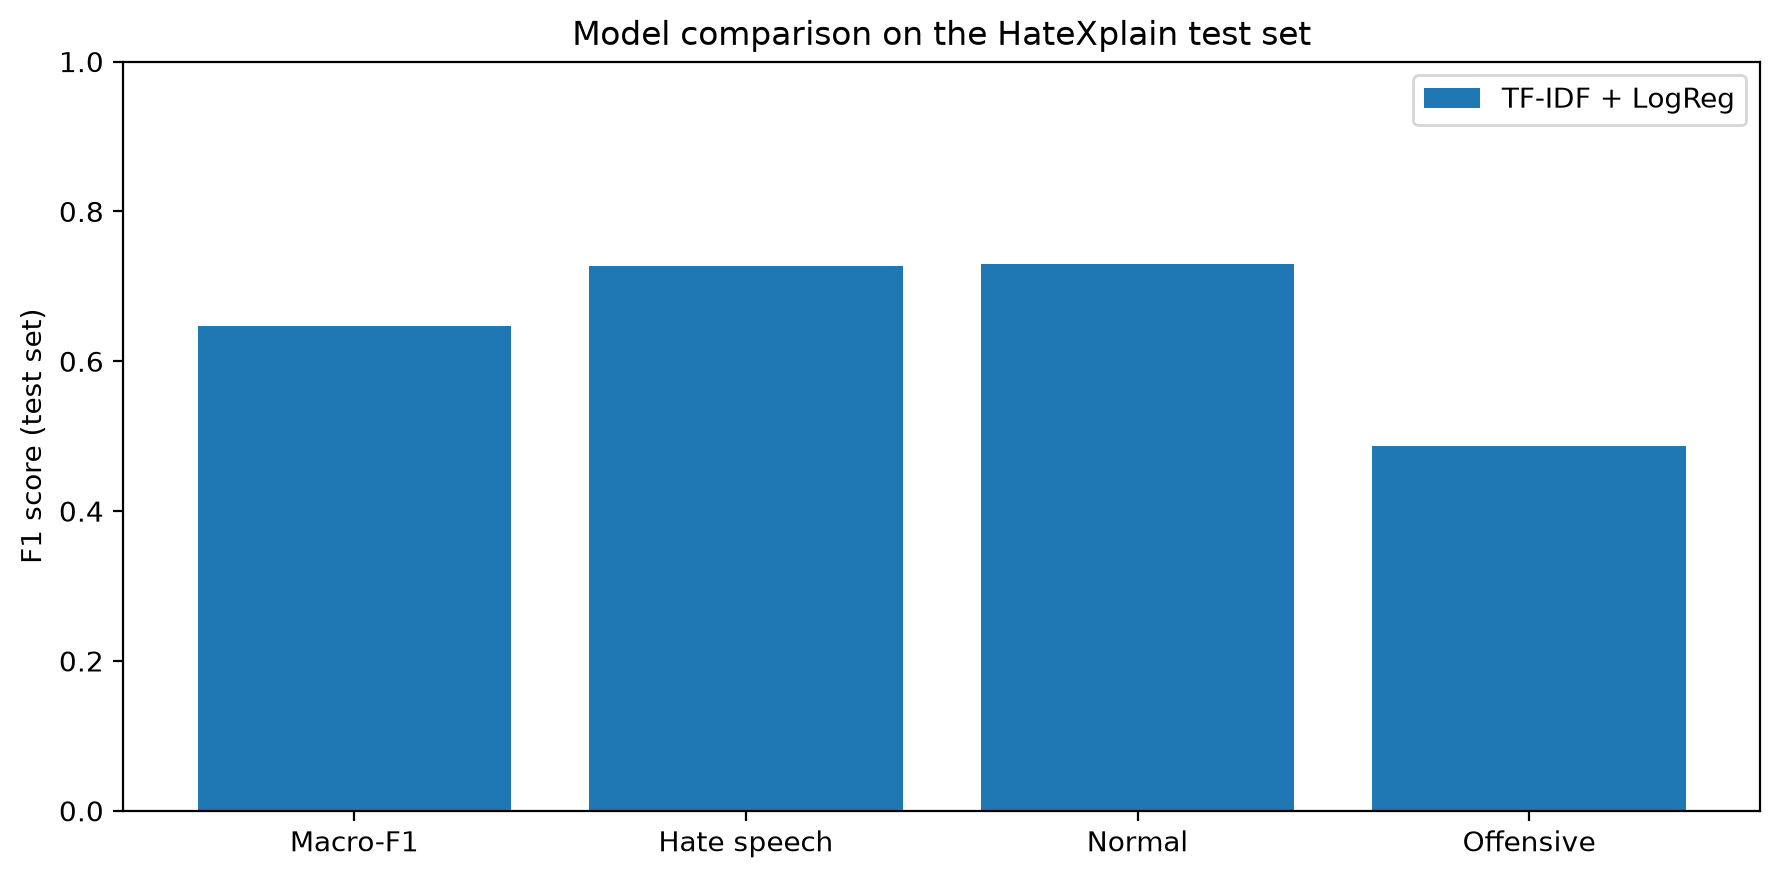

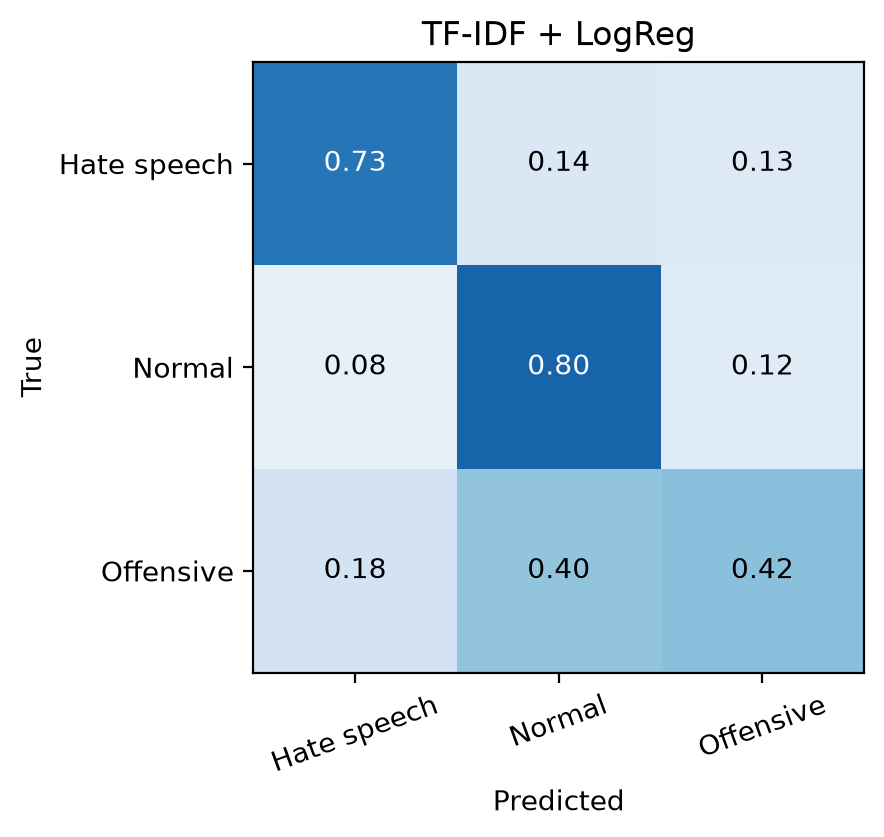

In [4]:
display(pd.read_csv(TABLES_DIR / "model_comparison.csv").round(3))
display(Image(str(FIGURES_DIR / "model_comparison.png")))
display(Image(str(FIGURES_DIR / "confusion_matrices_all.png")))

## Where does the best model go wrong?

,true_name,pred_name,count,share_of_errors
0,Offensive,Normal,219,0.344
1,Offensive,Hate speech,99,0.155
2,Normal,Offensive,93,0.146
3,Hate speech,Normal,86,0.135
4,Hate speech,Offensive,75,0.118
5,Normal,Hate speech,65,0.102


,agreement,posts,accuracy
0,all 3 agree,974,0.787
1,split 2-1,950,0.547


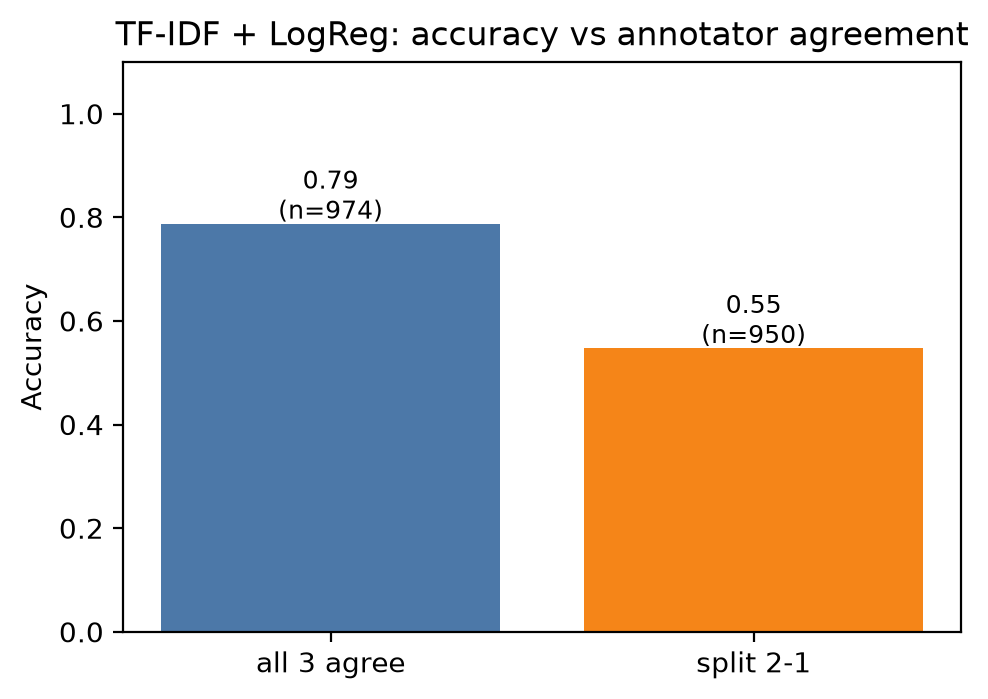

,length_bin,posts,accuracy
0,1-10,394,0.703
1,11-20,585,0.662
2,21-30,376,0.694
3,31+,569,0.636


In [5]:
display(pd.read_csv(TABLES_DIR / "error_confusion_pairs.csv"))
display(pd.read_csv(TABLES_DIR / "error_by_annotator_agreement.csv").round(3))
display(Image(str(FIGURES_DIR / "error_by_agreement.png")))
display(pd.read_csv(TABLES_DIR / "error_by_length.csv").round(3))

## Most confident mistakes (read these and write 3-4 conclusions for the report)

In [6]:
pd.set_option("display.max_colwidth", 140)
pd.read_csv(TABLES_DIR / "error_examples.csv")

,id,text,true_name,pred_name,confidence,annotator_labels
0,1080578011047571473_twitter,<user> <user> how can a refugee cross any border illegally asking for people who need help,Offensive,Normal,0.940,"[1, 2, 2]"
1,1144486239434788864_twitter,<user> <user> i can ’ t stand this look they all look like identical blow up dolls,Offensive,Normal,0.896,"[2, 2, 1]"
2,1179102478710837249_twitter,<user> i am black with all white freinds taco man,Offensive,Normal,0.890,"[2, 2, 2]"
3,1210935943395495938_twitter,<user> i fucking hate you yzm 😂,Offensive,Normal,0.860,"[2, 2, 0]"
4,12777328_gab,we could update the refugee law if a refugee kills someone then <number> people from that refugee country are deported each time it happ...,Offensive,Normal,0.847,"[2, 2, 2]"
5,1237773908570509313_twitter,<user> normalize hating white people,Offensive,Normal,0.840,"[2, 0, 2]"
6,1179074111076814848_twitter,<user> lmao 😂 eses charged me under <money> fuck them white folk lmao,Offensive,Normal,0.837,"[2, 2, 2]"
7,10682437_gab,<user> puppy no i was alone i am not a nazi white supremacist or any other type of person i am <number> southern i support traditional v...,Offensive,Normal,0.837,"[2, 2, 1]"
8,1079092016158593024_twitter,arsenal is a fucking small club with a lot of noise makers called fans livars,Offensive,Normal,0.834,"[2, 2, 1]"
9,1178598150002466816_twitter,<user> <user> <user> absolutely right man legal immigrants who work hard and and are law abiding citizens are not the problem the contex...,Offensive,Normal,0.832,"[2, 1, 2]"


## Notes for the report
- Which class is hardest and why? (look at the confusion pairs)
- Do mistakes concentrate on posts where the 3 annotators disagreed? (agreement table)
- Do the confident mistakes look like label noise, sarcasm, reclaimed slurs, or identity terms in neutral posts?